<center> <img src = https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/hh%20label.jpg alt="drawing" style="width:400px;">

# <center> Проект: Анализ резюме из HeadHunter
   

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла. 

In [2]:
# Файлы данных лежат рядом с ноутбуком.
df = pd.read_csv('dst-3.0_16_1_hh_database.csv', sep=';')
df.head()


                                   Пол, возраст  ...                            Авто
0    Мужчина ,  39 лет , родился 27 ноября 1979  ...  Имеется собственный автомобиль
1     Мужчина ,  60 лет , родился 20 марта 1959  ...                      Не указано
2  Женщина ,  36 лет , родилась 12 августа 1982  ...                      Не указано
3      Мужчина ,  38 лет , родился 25 июня 1980  ...                      Не указано
4     Женщина ,  26 лет , родилась 3 марта 1993  ...                      Не указано

[5 rows x 12 columns]

2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [3]:
df.head(5)

                                   Пол, возраст  ...                            Авто
0    Мужчина ,  39 лет , родился 27 ноября 1979  ...  Имеется собственный автомобиль
1     Мужчина ,  60 лет , родился 20 марта 1959  ...                      Не указано
2  Женщина ,  36 лет , родилась 12 августа 1982  ...                      Не указано
3      Мужчина ,  38 лет , родился 25 июня 1980  ...                      Не указано
4     Женщина ,  26 лет , родилась 3 марта 1993  ...                      Не указано

[5 rows x 12 columns]

3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Пол, возраст                     44744 non-null  object
 1   ЗП                               44744 non-null  object
 2   Ищет работу на должность:        44744 non-null  object
 3   Город, переезд, командировки     44744 non-null  object
 4   Занятость                        44744 non-null  object
 5   График                           44744 non-null  object
 6   Опыт работы                      44576 non-null  object
 7   Последнее/нынешнее место работы  44743 non-null  object
 8   Последняя/нынешняя должность     44742 non-null  object
 9   Образование и ВУЗ                44744 non-null  object
 10  Обновление резюме                44744 non-null  object
 11  Авто                             44744 non-null  object
dtypes: object(12)
memory usage: 4.1+

4. Обратите внимание на информацию о числе непустых значений.

5. Выведите основную статистическую информацию о столбцах.


In [5]:
df.describe()

                                         Пол, возраст  ...        Авто
count                                           44744  ...       44744
unique                                          16003  ...           2
top     Мужчина ,  32 года , родился 17 сентября 1986  ...  Не указано
freq                                               18  ...       32268

[4 rows x 12 columns]

# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование, ответьте на контрольные вопросы и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [6]:


def education(education_university):

    words = education_university.split()
    start = ' '.join(words[:2]).lower()

    if 'неоконченное высшее' in start:
        return 'неоконченное высшее'
    elif 'высшее' in start:
        return 'высшее'
    elif 'среднее специальное' in start:
        return 'среднее специальное'
    elif 'среднее' in start:
        return 'среднее'


df['Образование'] = df['Образование и ВУЗ'].apply(education)

print(df['Образование'].unique())
print(df['Образование'].value_counts())

df = df.drop(columns=['Образование и ВУЗ'])


['неоконченное высшее' 'высшее' 'среднее специальное' 'среднее']
Образование
высшее                 33863
среднее специальное     5765
неоконченное высшее     4557
среднее                  559
Name: count, dtype: int64


2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979 
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина. 
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование, ответьте на контрольные вопросы и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '. 
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [7]:
def get_gender(gender_age):

    words = gender_age.split()
    first_word = words[0].lower()

    if 'мужчина' in first_word:
        return 'М'
    elif 'женщина' in first_word:
        return 'Ж'


df['Пол'] = df['Пол, возраст'].apply(get_gender)


def get_age(gender_age):

    age_part = gender_age.split(',')[1]
    age_words = age_part.split()
    age = int(age_words[0])
    return age


df['Возраст'] = df['Пол, возраст'].apply(get_age)


print(df['Пол'].unique())
print(df['Пол'].value_counts())

df = df.drop(columns=['Пол, возраст'])


['М' 'Ж']
Пол
М    36211
Ж     8533
Name: count, dtype: int64


3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**. 

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование, ответьте на контрольные вопросы и удалите столбец **"Опыт работы"** из таблицы.


In [8]:
def get_experience(experience):
    if pd.isna(experience) or experience.startswith('Не указан'):
        return np.nan

    words = experience.split()[2:6]
    if len(words) < 2:
        return np.nan
    if words[1].startswith(('лет', 'год')):
        years = int(words[0])
        months = 0
        if len(words) >= 4 and words[3].startswith('мес'):
            months = int(words[2])
        return years * 12 + months
    if words[1].startswith('мес'):
        return int(words[0])
    return np.nan


df['Опыт работы (мес)'] = df['Опыт работы'].apply(get_experience)
df = df.drop(columns=['Опыт работы'])


4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , … 
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [9]:
million_cities = [
    'Новосибирск', 'Екатеринбург', 'Нижний Новгород', 'Казань',
    'Челябинск', 'Омск', 'Самара', 'Ростов-на-Дону', 'Уфа',
    'Красноярск', 'Пермь', 'Воронеж', 'Волгоград'
]


def get_city(location):
    city = location.split(',')[0].strip()
    if city in ['Москва', 'Санкт-Петербург']:
        return city
    if city in million_cities:
        return 'город-миллионник'
    return 'другое'


location = df['Город, переезд, командировки'].fillna('')
df['Город'] = location.apply(get_city)
df['Готовность к переезду'] = (
    location.str.contains(r'готова? к переезду|хочу переехать', case=False)
    & ~location.str.contains(r'не готова? к переезду', case=False)
)
df['Готовность к командировкам'] = (
    location.str.contains(r'готова? к (?:редким )?командировкам', case=False)
    & ~location.str.contains(
        r'не готова? к (?:редким )?командировкам', case=False
    )
)
df = df.drop(columns=['Город, переезд, командировки'])
print(df['Город'].value_counts())


Город
Москва              16621
другое              15854
город-миллионник     7332
Санкт-Петербург      4937
Name: count, dtype: int64


5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:
<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/ohe.jpg>
Выполните данное преобразование для признаков "Занятость" и "График", ответьте на контрольные вопросы, после чего удалите их из таблицы

In [10]:
employment_list = [
    'полная занятость', 'частичная занятость', 'проектная работа',
    'волонтерство', 'стажировка'
]
schedule_list = [
    'полный день', 'сменный график', 'гибкий график',
    'удаленная работа', 'вахтовый метод'
]


def has_category(text, category):
    return category in text


for category in employment_list:
    df[category] = df['Занятость'].apply(has_category, args=(category,))

for category in schedule_list:
    df[category] = df['График'].apply(has_category, args=(category,))

df = df.drop(columns=['Занятость', 'График'])


6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**. 
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата, 
* "proportion" - пропорция, 
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.

<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/table.jpg>


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После ответа на контрольные вопросы удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Итак, давайте обсудим возможный алгоритм преобразования: 
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [11]:
# Курс на дату обновления резюме за одну единицу валюты.
exchange_rates = pd.read_csv('ExchangeRates.csv')
exchange_rates['date'] = pd.to_datetime(
    exchange_rates['date'], format='%d/%m/%y'
)
exchange_rates['rate'] = exchange_rates['close'] / exchange_rates['proportion']

currency_codes = {
    'руб.': 'RUB', 'бел.руб.': 'BYN', 'грн.': 'UAH', 'сум': 'UZS',
    'KZT': 'KZT', 'USD': 'USD', 'EUR': 'EUR', 'KGS': 'KGS', 'AZN': 'AZN'
}
df['ЗП сумма'] = df['ЗП'].str.split().str[0].astype(int)
df['ЗП валюта'] = df['ЗП'].str.split().str[1].map(currency_codes)
df['Дата'] = pd.to_datetime(
    df['Обновление резюме'], format='%d.%m.%Y %H:%M'
).dt.normalize()

# Проверяем сопоставление валют и уникальность курсов.
print('Валют без ISO-кода:', df['ЗП валюта'].isna().sum())
df = df.merge(
    exchange_rates[['currency', 'date', 'rate']], how='left',
    left_on=['ЗП валюта', 'Дата'], right_on=['currency', 'date'],
    validate='many_to_one'
)
df.loc[df['ЗП валюта'] == 'RUB', 'rate'] = 1
print('Зарплат без курса:', df['rate'].isna().sum())
df['ЗП (руб)'] = df['ЗП сумма'] * df['rate']
df = df.drop(columns=[
    'ЗП', 'ЗП сумма', 'ЗП валюта', 'Дата', 'currency', 'date', 'rate'
])
df.head()


Валют без ISO-кода: 0
Зарплат без курса: 0


                           Ищет работу на должность:  ...  ЗП (руб)
0                            Системный администратор  ...   29000.0
1                               Технический писатель  ...   40000.0
2                                           Оператор  ...   20000.0
3  Веб-разработчик (HTML / CSS / JS / PHP / базы ...  ...  100000.0
4                  Региональный менеджер по продажам  ...  140000.0

[5 rows x 23 columns]

# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

Мода: [30]
Минимальный возраст: 14
Максимальный возраст: 100
Медиана: 31.0
Первый и третий квартили: {0.25: 27.0, 0.75: 36.0}
Доля соискателей от 20 до 40 лет: 85.4%


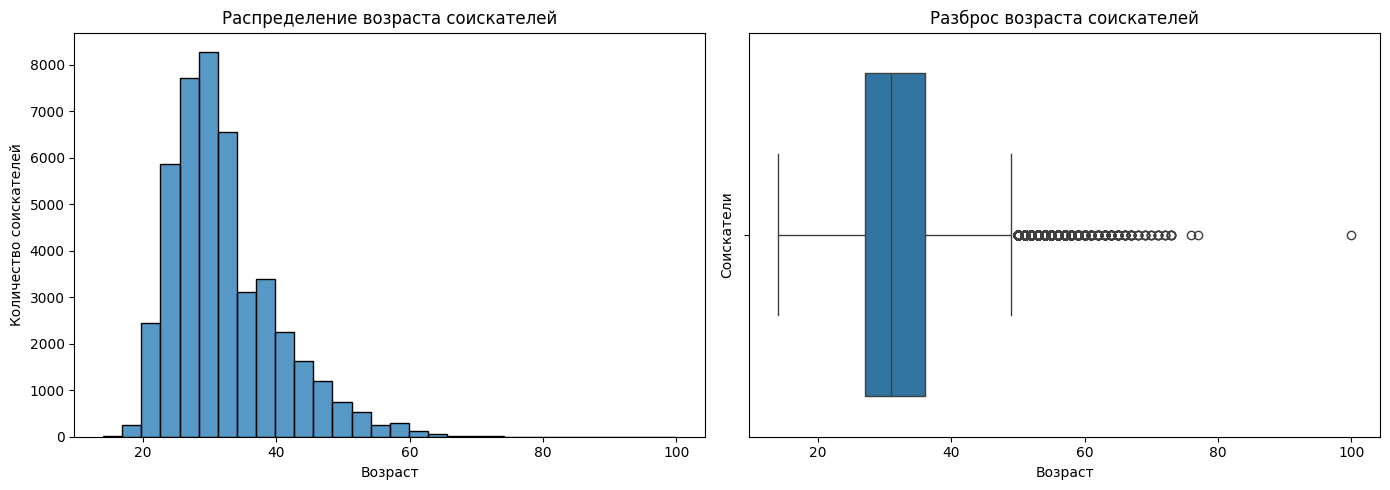

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='Возраст', bins=30, ax=axes[0])
axes[0].set_title('Распределение возраста соискателей')
axes[0].set_ylabel('Количество соискателей')

sns.boxplot(data=df, x='Возраст', ax=axes[1])
axes[1].set_title('Разброс возраста соискателей')
axes[1].set_ylabel('Соискатели')

plt.tight_layout()
plt.show()

age = df['Возраст']
print('Мода:', age.mode().tolist())
print('Минимальный возраст:', age.min())
print('Максимальный возраст:', age.max())
print('Медиана:', age.median())
print('Первый и третий квартили:', age.quantile([0.25, 0.75]).to_dict())
print(f'Доля соискателей от 20 до 40 лет: {age.between(20, 40).mean():.1%}')


Возраст соискателей составляет от **14 до 100 лет**. Самый распространённый возраст — **30 лет**, медиана — **31 год**. Около **85,4%** соискателей находятся в возрасте от 20 до 40 лет; у половины возраст составляет от 27 до 36 лет.

Распределение имеет правый хвост: среди более старших возрастов число соискателей постепенно уменьшается. Потенциальной аномалией выглядит возраст **100 лет** — исходную запись стоит проверить. Необычное значение само по себе не доказывает ошибку в данных.


2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

Мода стажа: 81.0
Минимальный стаж: 1.0
Максимальный стаж: 1188.0 мес. (99.0 лет)
Квартиль 25%: 57.0, квартиль 75%: 154.0


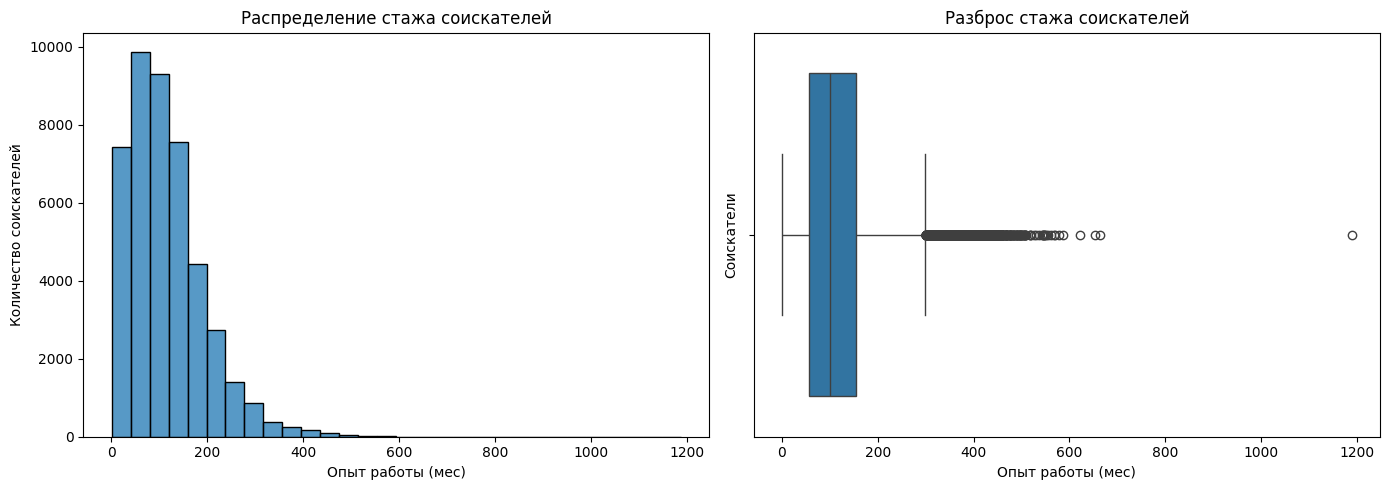

In [13]:
stage = df['Опыт работы (мес)']

mode_stage = stage.mode()[0]
print(f'Мода стажа: {mode_stage}')

min_stage = stage.min()
print(f'Минимальный стаж: {min_stage}')

max_stage = stage.max()
print(f'Максимальный стаж: {max_stage} мес. ({max_stage / 12:.1f} лет)')

q25 = stage.quantile(0.25)
q75 = stage.quantile(0.75)
print(f'Квартиль 25%: {q25}, квартиль 75%: {q75}')



fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='Опыт работы (мес)', bins=30, ax=axes[0])
axes[0].set_title('Распределение стажа соискателей')
axes[0].set_ylabel('Количество соискателей')

sns.boxplot(data=df, x='Опыт работы (мес)', ax=axes[1])
axes[1].set_title('Разброс стажа соискателей')
axes[1].set_ylabel('Соискатели')

plt.tight_layout()
plt.show()

Опыт работы соискателей составляет от **1 до 1188 месяцев**. Чаще всего встречается опыт **81 месяц** — 6 лет и 9 месяцев. Медианный опыт составляет **100 месяцев**, или 8 лет и 4 месяца.

У половины соискателей опыт находится в интервале от **57 до 154 месяцев** — примерно от 5 до 13 лет. Это границы первого и третьего квартилей. Распределение имеет правый хвост: большие значения опыта встречаются реже.

Потенциальная аномалия — **1188 месяцев**, или 99 лет опыта


3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для признака возраста? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


Минимальная зарплата: 1 руб.
Максимальная зарплата: 24,304,876 руб.
Медианная зарплата: 59,019 руб.
Первый и третий квартили, руб.:
0.25    37082.2
0.75    95000.0
Name: ЗП (руб), dtype: float64
Зарплат ниже 1 000 руб.: 84
Зарплат выше 1 000 000 руб.: 5


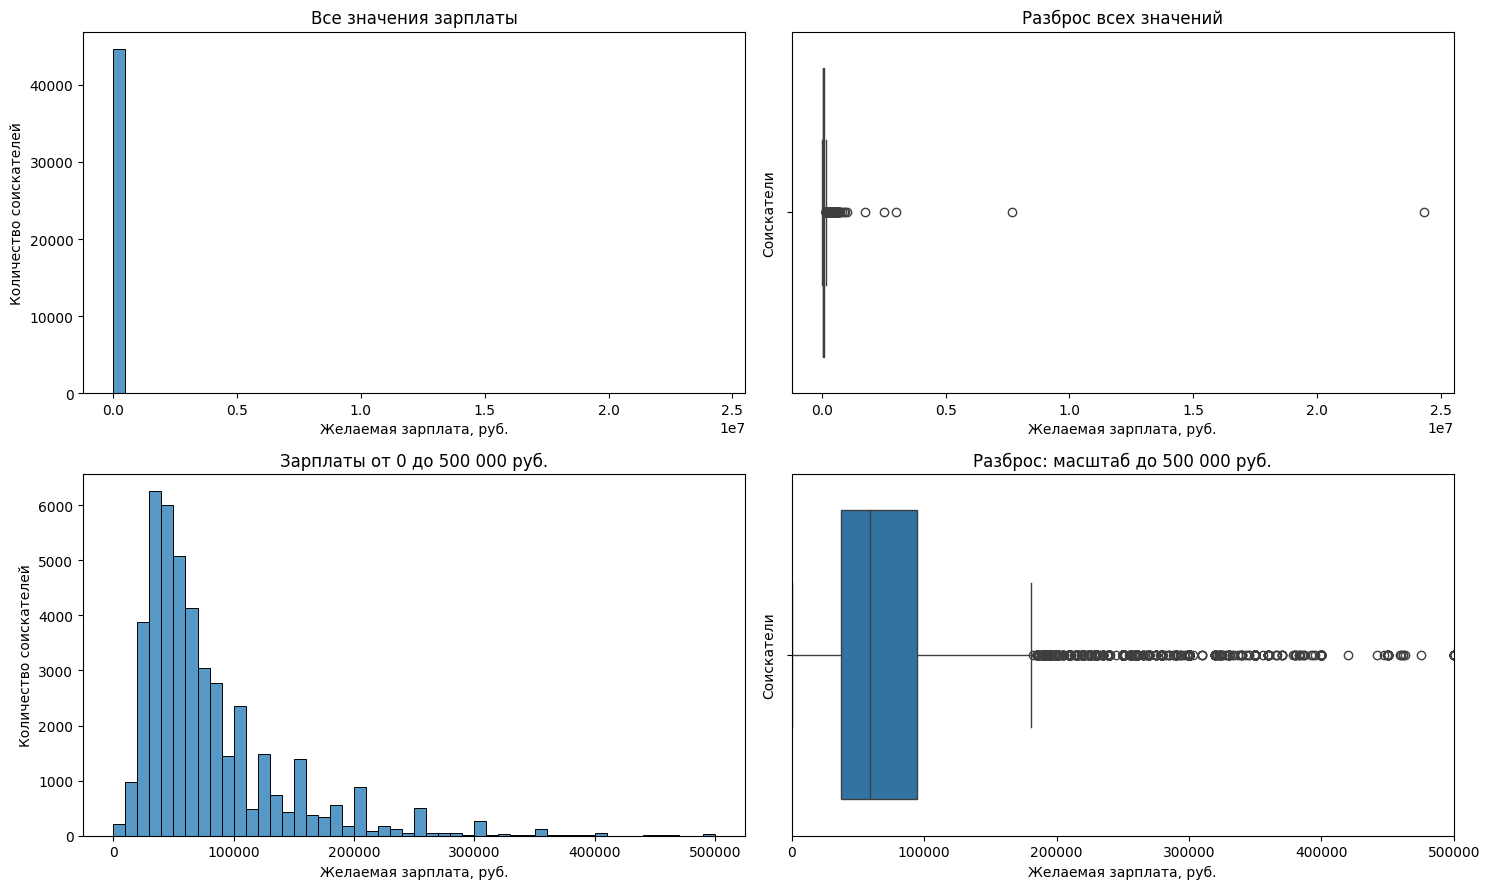

In [14]:
salary = df['ЗП (руб)']

print(f'Минимальная зарплата: {salary.min():,.0f} руб.')
print(f'Максимальная зарплата: {salary.max():,.0f} руб.')
print(f'Медианная зарплата: {salary.median():,.0f} руб.')
print('Первый и третий квартили, руб.:')
print(salary.quantile([0.25, 0.75]).round(2))
print(f'Зарплат ниже 1 000 руб.: {(salary < 1_000).sum()}')
print(f'Зарплат выше 1 000 000 руб.: {(salary > 1_000_000).sum()}')




fig, axes = plt.subplots(2, 2, figsize=(15, 9))

sns.histplot(salary, bins=50, ax=axes[0, 0])
axes[0, 0].set_title('Все значения зарплаты')
axes[0, 0].set_xlabel('Желаемая зарплата, руб.')
axes[0, 0].set_ylabel('Количество соискателей')

sns.boxplot(x=salary, ax=axes[0, 1])
axes[0, 1].set_title('Разброс всех значений')
axes[0, 1].set_xlabel('Желаемая зарплата, руб.')
axes[0, 1].set_ylabel('Соискатели')

sns.histplot(salary, bins=range(0, 500_001, 10_000), ax=axes[1, 0])
axes[1, 0].set_title('Зарплаты от 0 до 500 000 руб.')
axes[1, 0].set_xlabel('Желаемая зарплата, руб.')
axes[1, 0].set_ylabel('Количество соискателей')

sns.boxplot(x=salary, ax=axes[1, 1])
axes[1, 1].set_xlim(0, 500_000)
axes[1, 1].set_title('Разброс: масштаб до 500 000 руб.')
axes[1, 1].set_xlabel('Желаемая зарплата, руб.')
axes[1, 1].set_ylabel('Соискатели')

plt.tight_layout()
plt.show()


Желаемая зарплата составляет от **1 до 24 304 876 руб.**, медиана — **59 019 руб.** У половины соискателей она находится между **37 082 и 95 000 руб.**

Распределение имеет выраженный правый хвост: большинство значений сосредоточено в нижней части диапазона, а отдельные очень высокие зарплаты растягивают шкалу. Поэтому наряду с полным диапазоном показан увеличенный фрагмент до 500 000 руб.; на двух нижних графиках значения выше этого порога не видны.

Потенциальные аномалии — крайне низкие и высокие значения: **84** зарплаты ниже 1 000 руб. и **5** выше 1 млн руб. Их следует проверить; сами по себе необычные значения ещё не доказывают ошибку. Вопрос об аномалиях возраста в условии, вероятно, является опечаткой: здесь анализируется зарплата.


4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

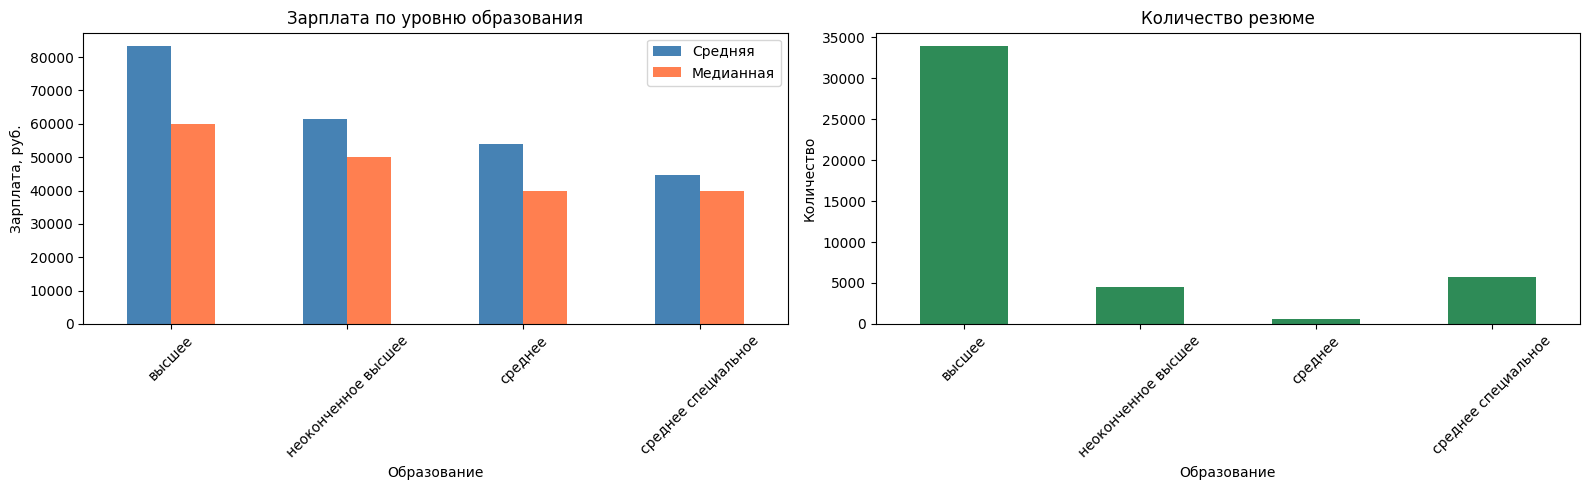

In [15]:
df4 = df[df['ЗП (руб)'] < 1_000_000]

education_salary = (
    df4.groupby('Образование')['ЗП (руб)']
    .agg(['mean', 'median', 'count'])
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Средняя и медианная зарплата
education_salary[['mean', 'median']].plot(
    kind='bar',
    ax=axes[0],
    color=['steelblue', 'coral']
)
axes[0].set_title('Зарплата по уровню образования')
axes[0].set_xlabel('Образование')
axes[0].set_ylabel('Зарплата, руб.')
axes[0].legend(['Средняя', 'Медианная'])
axes[0].tick_params(axis='x', rotation=45)

# Количество резюме
education_salary['count'].plot(
    kind='bar',
    ax=axes[1],
    color='seagreen'
)
axes[1].set_title('Количество резюме')
axes[1].set_xlabel('Образование')
axes[1].set_ylabel('Количество')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


**Вывод.** Среди резюме с желаемой зарплатой меньше 1 млн руб. самая высокая медианная зарплата у соискателей с высшим образованием — **60 000 руб.** У соискателей с неоконченным высшим образованием медиана составляет **50 000 руб.**, со средним и средним специальным — по **40 000 руб.**

Уровень образования может быть полезным признаком при прогнозировании желаемой зарплаты: медианы различаются. Однако на зарплатные ожидания могут влиять опыт, профессия и город, поэтому полезность признака нужно проверить на модели. Сравниваются желаемые, а не фактические зарплаты.


5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

                   median  <lambda_0>  <lambda_1>
Город                                            
Москва            85000.0    60000.00    150000.0
Санкт-Петербург   60000.0    44772.14     85000.0
город-миллионник  40000.0    30000.00     60000.0
другое            40000.0    30000.00     60000.0


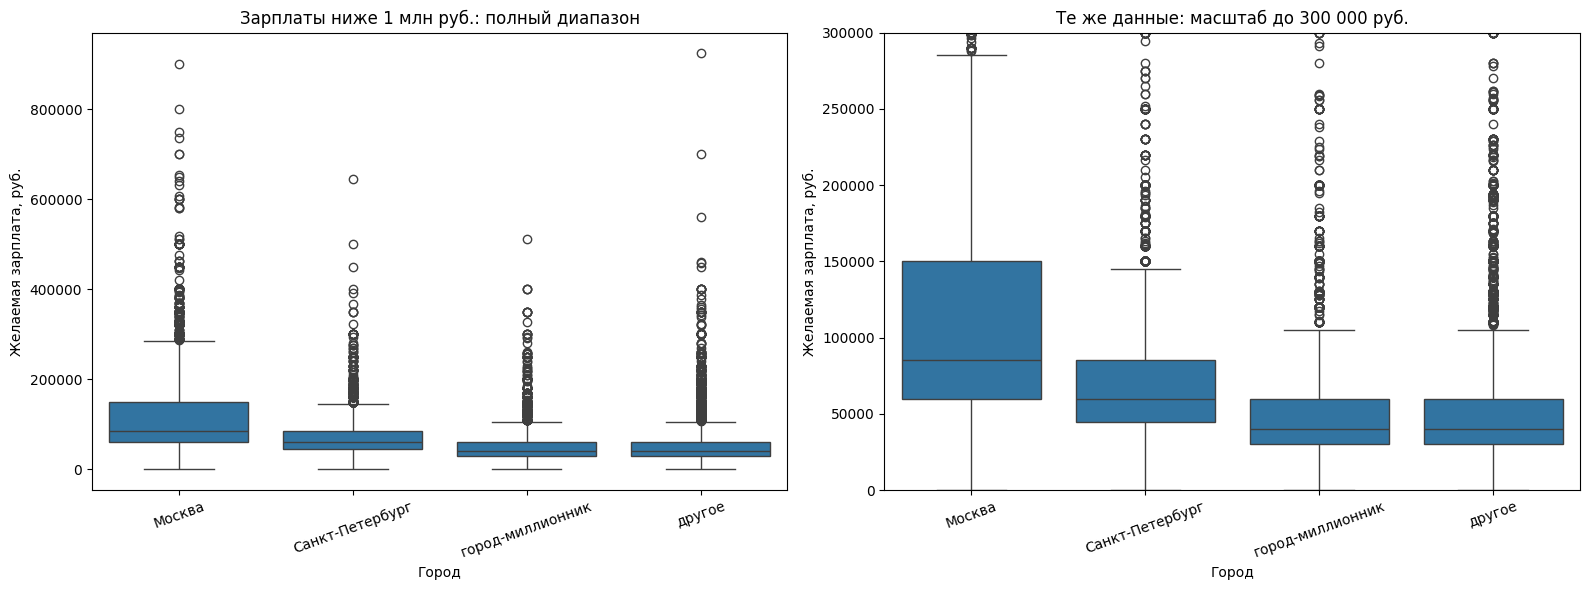

In [16]:
city_salary = df[df['ЗП (руб)'] < 1_000_000]
city_order = ['Москва', 'Санкт-Петербург', 'город-миллионник', 'другое']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax in axes:
    sns.boxplot(
        data=city_salary, x='Город', y='ЗП (руб)',
        order=city_order, ax=ax
    )
    ax.set_xlabel('Город')
    ax.set_ylabel('Желаемая зарплата, руб.')
    ax.tick_params(axis='x', rotation=20)

axes[0].set_title('Зарплаты ниже 1 млн руб.: полный диапазон')
axes[1].set_title('Те же данные: масштаб до 300 000 руб.')
axes[1].set_ylim(0, 300_000)
plt.tight_layout()
plt.show()

print(city_salary.groupby('Город')['ЗП (руб)'].agg(
    ['median', lambda values: values.quantile(0.25),
     lambda values: values.quantile(0.75)]
))


**Вывод.** Самая высокая медианная желаемая зарплата среди резюме с зарплатой меньше 1 млн руб. указана в Москве — **85 000 руб.**, затем в Санкт-Петербурге — **60 000 руб.** В городах-миллионниках и категории «другое» медиана составляет по **40 000 руб.**

Разброс центральной половины зарплат наиболее широк в Москве: **60 000–150 000 руб.** В Санкт-Петербурге этот интервал составляет примерно **44 772–85 000 руб.**, а в двух остальных группах — **30 000–60 000 руб.** Границы рассчитаны по первому и третьему квартилям.

Город может быть полезным признаком для прогнозирования желаемой зарплаты, но его вклад нужно проверить на модели с учётом профессии, опыта и других факторов.


6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

 Готовность к переезду  Готовность к командировкам    median  count
                 False                       False 40000.000  11337
                 False                        True 60000.000  17382
                  True                       False 50000.000   1767
                  True                        True 65849.455  14258


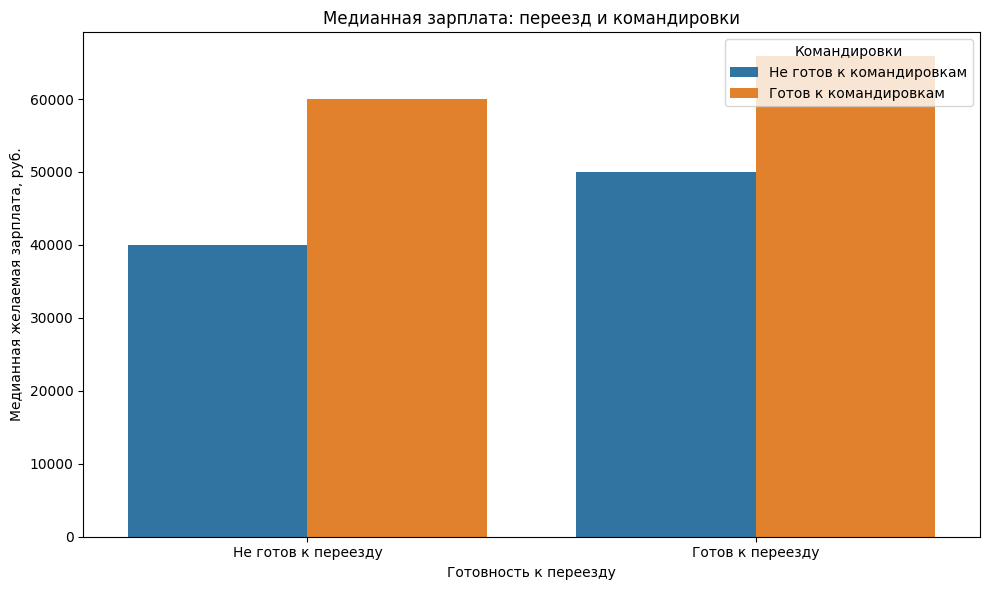

In [17]:
# Медиана и число резюме для каждой комбинации признаков.
readiness_salary = (
    df.groupby(['Готовность к переезду', 'Готовность к командировкам'])
    ['ЗП (руб)']
    .agg(['median', 'count'])
    .reset_index()
)
print(readiness_salary.to_string(index=False))

chart_data = readiness_salary.copy()
chart_data['Переезд'] = chart_data['Готовность к переезду'].map({
    False: 'Не готов к переезду', True: 'Готов к переезду'
})
chart_data['Командировки'] = chart_data['Готовность к командировкам'].map({
    False: 'Не готов к командировкам', True: 'Готов к командировкам'
})

plt.figure(figsize=(10, 6))
sns.barplot(data=chart_data, x='Переезд', y='median', hue='Командировки',
            order=['Не готов к переезду', 'Готов к переезду'],
            hue_order=['Не готов к командировкам', 'Готов к командировкам'])
plt.title('Медианная зарплата: переезд и командировки')
plt.xlabel('Готовность к переезду')
plt.ylabel('Медианная желаемая зарплата, руб.')
plt.legend(title='Командировки')
plt.tight_layout()
plt.show()


**Вывод.** Самая высокая медианная желаемая зарплата у соискателей, готовых и к переезду, и к командировкам, — около **65 849 руб.** У готовых к командировкам, но не к переезду медиана составляет **60 000 руб.**; у готовых к переезду, но не к командировкам — **50 000 руб.**; у не готовых ни к тому ни к другому — **40 000 руб.**

В обеих группах по готовности к переезду медианная зарплата выше у готовых к командировкам. В обеих группах по командировкам она выше у готовых к переезду. Это описание связи, а не доказательство причины: на зарплатные ожидания могут влиять профессия, опыт и город. Сравниваются желаемые зарплаты без фильтра по их величине.


7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

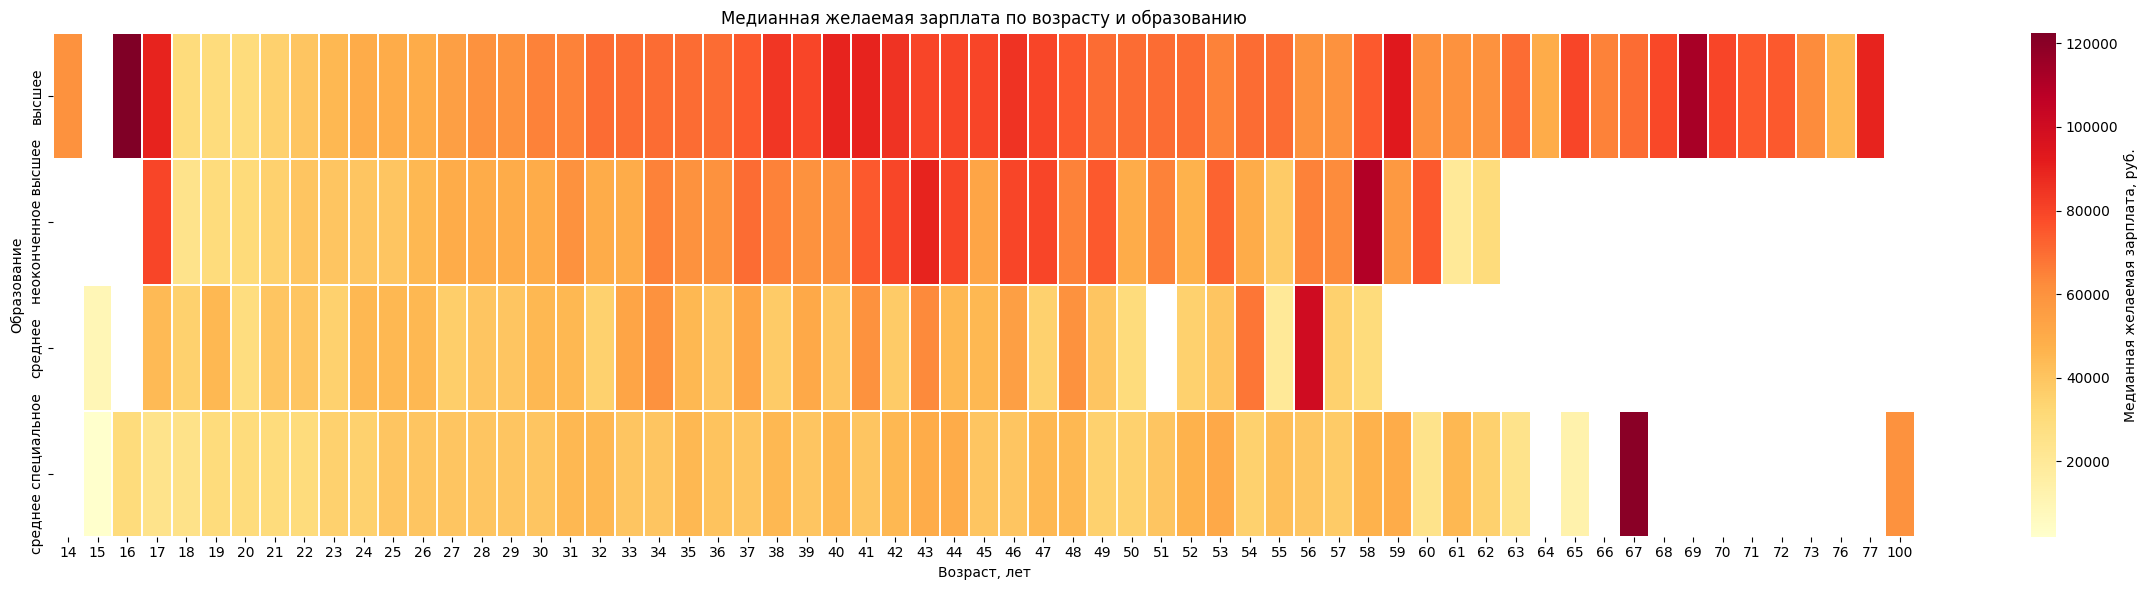

Возраст                   20       30       40
Образование                                   
высшее               30000.0  65000.0  90000.0
неоконченное высшее  31000.0  50000.0  60000.0
среднее              29000.0  45000.0  40000.0
среднее специальное  30000.0  40000.0  45000.0
Число резюме по возрасту:
Возраст
67     9
68     4
69     4
70     3
71     4
72     3
73     4
76     1
77     1
100    1


In [55]:
# Медианная зарплата по возрасту и образованию.
pivot_table = pd.pivot_table(
    df, index='Образование', columns='Возраст',
    values='ЗП (руб)', aggfunc='median'
)

fig, ax = plt.subplots(figsize=(24, 6))
sns.heatmap(
    pivot_table, cmap='YlOrRd', linewidths=0.3, ax=ax,
    cbar_kws={'label': 'Медианная желаемая зарплата, руб.'}
)
ax.set_title('Медианная желаемая зарплата по возрасту и образованию')
ax.set_xlabel('Возраст, лет')
ax.set_ylabel('Образование')
ax.tick_params(axis='x', labelrotation=0)
plt.tight_layout()
plt.show()

print(pivot_table[[20, 30, 40]].round(0).to_string())
print('Число резюме по возрасту:')
print(df['Возраст'].value_counts().sort_index().tail(10).to_string())


Медианная желаемая зарплата различается в зависимости от возраста и образования. Например, среди соискателей 30 лет медиана выше у группы с высшим образованием, чем у групп со средним и средним специальным образованием.

Отдельные крайние возраста представлены небольшим числом резюме, поэтому их медианы нестабильны. Пустые ячейки означают отсутствие резюме в группе. Сопоставление показывает связь, но не доказывает, что возраст или образование сами по себе вызывают различия в зарплатных ожиданиях.


8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

Резюме с опытом не меньше возраста: 7
Резюме без указанного опыта: 170


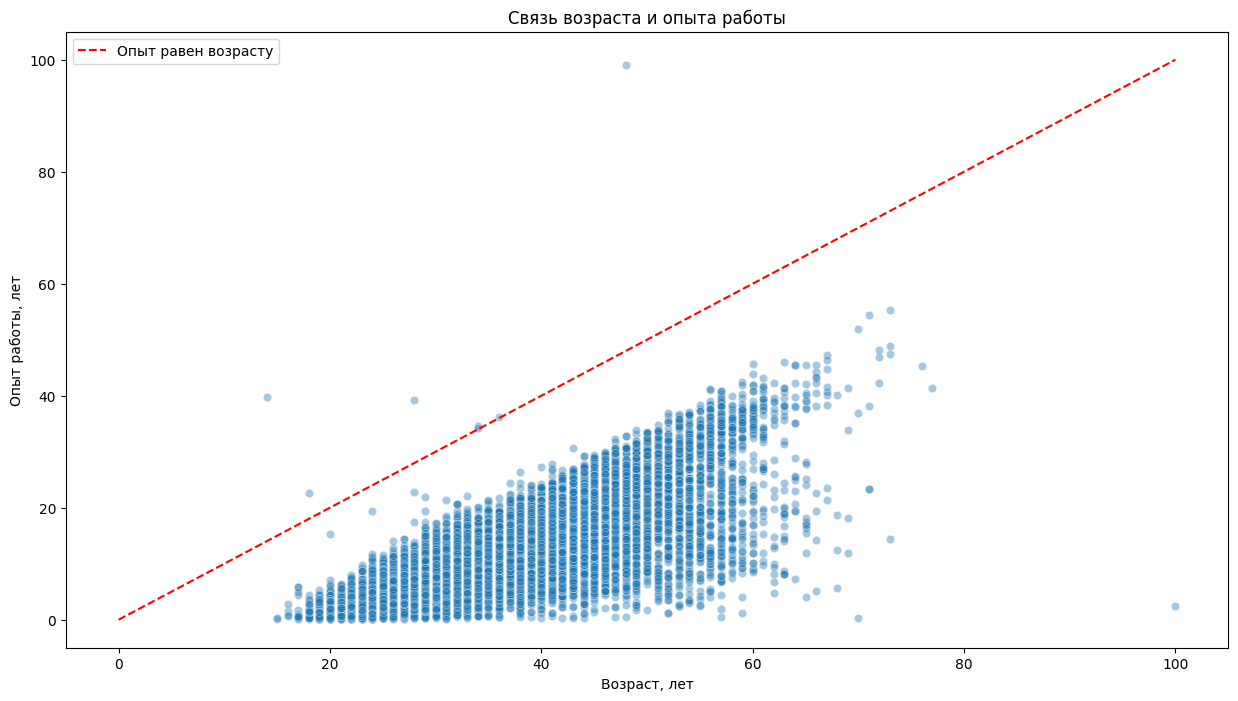

In [19]:
# Переводим опыт из месяцев в годы.
experience_years = df['Опыт работы (мес)'] / 12

fig, ax = plt.subplots(figsize=(15, 8))
sns.scatterplot(x=df['Возраст'], y=experience_years, alpha=0.4, ax=ax)

# На прямой опыт работы равен возрасту.
ax.plot(
    [0, 100], [0, 100], color='red', linestyle='--',
    label='Опыт равен возрасту'
)
ax.set_title('Связь возраста и опыта работы')
ax.set_xlabel('Возраст, лет')
ax.set_ylabel('Опыт работы, лет')
ax.legend()
plt.show()

anomalies = df[experience_years >= df['Возраст']]
print(f'Резюме с опытом не меньше возраста: {len(anomalies)}')
print(f'Резюме без указанного опыта: {experience_years.isna().sum()}')


**Вывод.** В целом с возрастом опыт работы увеличивается, хотя у соискателей одного возраста он может существенно различаться.

Выявлено **7 резюме**, в которых опыт работы больше либо равен возрасту соискателя; в этих данных во всех семи случаях он именно превышает возраст. Такие значения выглядят ошибочными и требуют проверки. У **170 резюме** опыт не указан, поэтому определить наличие такой аномалии для них нельзя.

Точки ниже красной линии также не обязательно корректны: например, опыт, лишь немного меньший возраста, может быть нереалистичным с учётом возраста начала работы. Прямая показывает только условие из задания.


**Дополнительные баллы**

Для получения 2 дополнительных баллов по разведывательному анализу постройте еще два любых содержательных графика или диаграммы, которые помогут проиллюстрировать влияние признаков/взаимосвязь между признаками/распределения признаков. Приведите выводы по ним. Желательно, чтобы в анализе участвовали признаки, которые мы создавали ранее в разделе "Преобразование данных".


Медианы: {'Полная занятость': np.float64(60000.0), 'Частичная занятость': np.float64(50000.0)}
Число резюме: {'Полная занятость': np.int64(43284), 'Частичная занятость': np.int64(13136)}


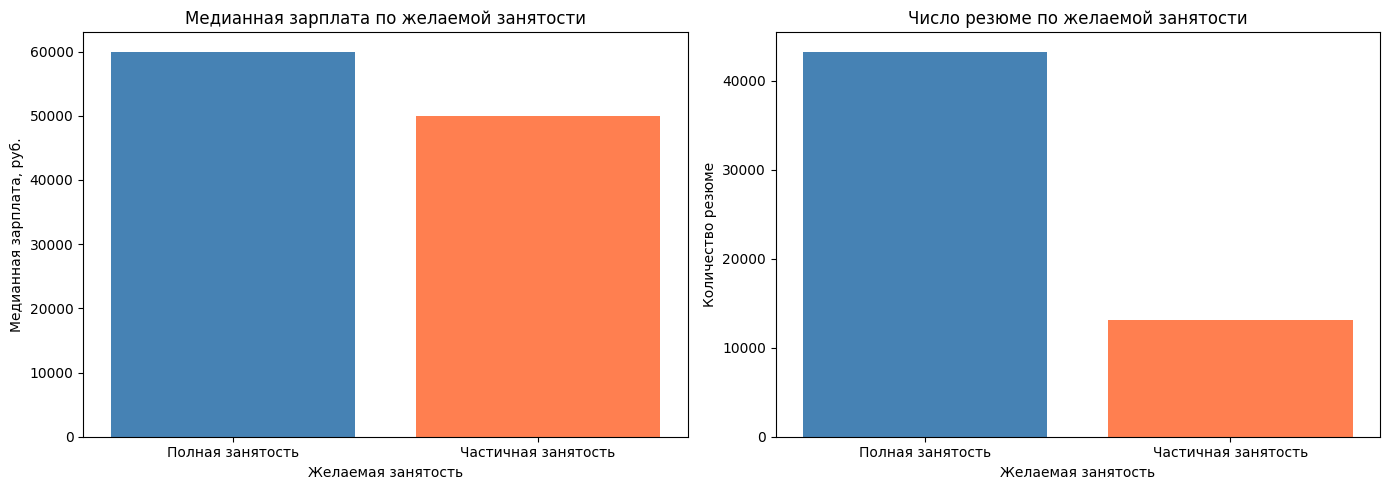

In [20]:
# Категории занятости могут пересекаться: один соискатель может выбрать обе.
employment_medians = []
employment_counts = []
for category in ['полная занятость', 'частичная занятость']:
    selected = df.loc[df[category], 'ЗП (руб)']
    employment_medians.append(selected.median())
    employment_counts.append(selected.count())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = ['Полная занятость', 'Частичная занятость']
axes[0].bar(labels, employment_medians, color=['steelblue', 'coral'])
axes[0].set_title('Медианная зарплата по желаемой занятости')
axes[0].set_xlabel('Желаемая занятость')
axes[0].set_ylabel('Медианная зарплата, руб.')
axes[1].bar(labels, employment_counts, color=['steelblue', 'coral'])
axes[1].set_title('Число резюме по желаемой занятости')
axes[1].set_xlabel('Желаемая занятость')
axes[1].set_ylabel('Количество резюме')
plt.tight_layout()
plt.show()
print('Медианы:', dict(zip(labels, employment_medians)))
print('Число резюме:', dict(zip(labels, employment_counts)))


Медианная желаемая зарплата среди указавших полную занятость составляет **60 000 руб.**  среди указавших частичную — **50 000 руб.** Число резюме в этих группах — 43 284 и 13 136 соответственно.

Один соискатель мог выбрать оба типа занятости  поэтому группы пересекаются. Разница медиан не доказывает влияния типа занятости на зарплату.


# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их. 

In [21]:
# Ищем полные дубликаты по всем столбцам и удаляем повторные строки.
duplicates_count = df.duplicated().sum()
print(f'Полных дубликатов: {duplicates_count}')
df = df.drop_duplicates().copy()
print(f'Осталось резюме: {len(df)}')


Полных дубликатов: 158
Осталось резюме: 44586


2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах. 

In [22]:
# Проверяем число пропусков по всем признакам.
missing_values = df.isna().sum().sort_values(ascending=False)
print('Пропуски по столбцам:')
print(missing_values.to_string())


Пропуски по столбцам:
Опыт работы (мес)                  168
Последняя/нынешняя должность         2
Последнее/нынешнее место работы      1
Ищет работу на должность:            0
частичная занятость                  0
вахтовый метод                       0
удаленная работа                     0
гибкий график                        0
сменный график                       0
полный день                          0
стажировка                           0
волонтерство                         0
проектная работа                     0
Готовность к командировкам           0
полная занятость                     0
Готовность к переезду                0
Город                                0
Возраст                              0
Пол                                  0
Образование                          0
Авто                                 0
Обновление резюме                    0
ЗП (руб)                             0


3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [23]:
# Удаляем строки без места работы или должности.
rows_before = len(df)
df = df.dropna(subset=[
    'Последнее/нынешнее место работы', 'Последняя/нынешняя должность'
]).copy()
print('Удалено резюме без места работы или должности:', rows_before - len(df))

# Медиану вычисляем после удаления строк, затем заполняем ею пропуски опыта.
experience_median = df['Опыт работы (мес)'].median()
experience_missing = df['Опыт работы (мес)'].isna().sum()
df['Опыт работы (мес)'] = df['Опыт работы (мес)'].fillna(experience_median)
print(f'Медианный опыт: {experience_median:.0f} мес.')
print(f'Заполнено пропусков: {experience_missing}')
print(f'Осталось резюме: {len(df)}')


Удалено резюме без места работы или должности: 2
Медианный опыт: 100 мес.
Заполнено пропусков: 168
Осталось резюме: 44584


4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [24]:
# Граничные значения 1 000 и 1 000 000 руб. остаются в данных.
salary_outliers = (df['ЗП (руб)'] < 1_000) | (df['ЗП (руб)'] > 1_000_000)
print(f'Резюме с зарплатой вне допустимых границ: {salary_outliers.sum()}')
df = df.loc[~salary_outliers].copy()
print(f'Осталось резюме: {len(df)}')


Резюме с зарплатой вне допустимых границ: 89
Осталось резюме: 44495


5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [25]:
# По условию этого пункта удаляем опыт строго больше возраста.
experience_outliers = df['Опыт работы (мес)'] / 12 > df['Возраст']
print(f'Резюме с опытом больше возраста: {experience_outliers.sum()}')
df = df.loc[~experience_outliers].copy()
print(f'Осталось резюме: {len(df)}')


Резюме с опытом больше возраста: 7
Осталось резюме: 44488


6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

Асимметрия логарифма возраста: 0.452
Границы возраста: 15.66 и 78.88 лет
Найдено выбросов по возрасту: 3
Выбросы (возраст, опыт и желаемая зарплата):
 Возраст  Опыт работы (мес)  ЗП (руб)
      15                2.0   10000.0
      15                3.0    2000.0
     100               30.0   60000.0
Осталось резюме после очистки: 44485


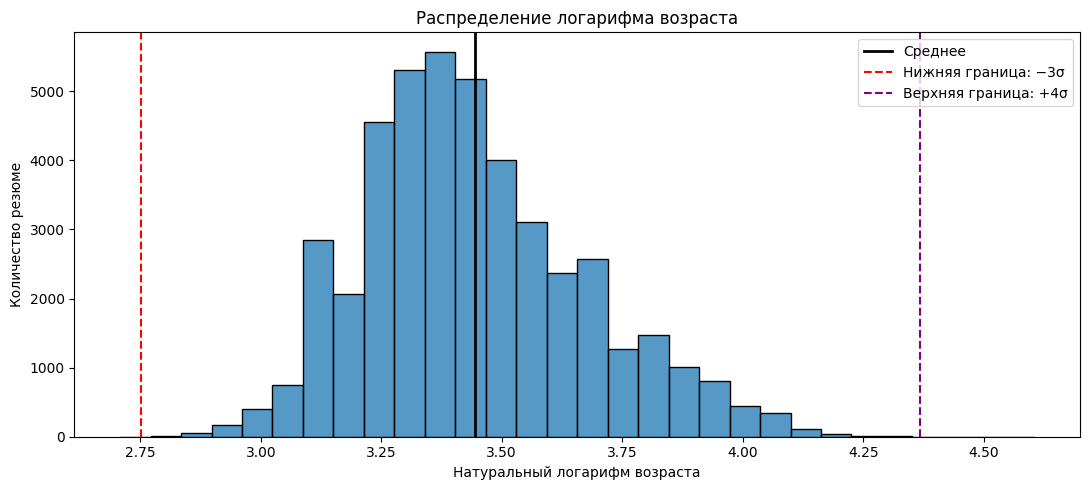

In [26]:
# Рассчитываем границы по логарифму возраста до удаления выбросов.
log_age = np.log(df['Возраст'])
log_mean = log_age.mean()
log_std = log_age.std()
lower_bound = log_mean - 3 * log_std
upper_bound = log_mean + 4 * log_std

fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(log_age, bins=30, ax=ax)
ax.axvline(log_mean, color='black', linewidth=2, label='Среднее')
ax.axvline(
    lower_bound, color='red', linestyle='--', label='Нижняя граница: −3σ'
)
ax.axvline(
    upper_bound, color='purple', linestyle='--', label='Верхняя граница: +4σ'
)
ax.set_title('Распределение логарифма возраста')
ax.set_xlabel('Натуральный логарифм возраста')
ax.set_ylabel('Количество резюме')
ax.legend()
plt.tight_layout()
plt.show()

age_outlier_mask = (log_age < lower_bound) | (log_age > upper_bound)
age_outliers = df.loc[age_outlier_mask].copy()
print(f'Асимметрия логарифма возраста: {log_age.skew():.3f}')
print(f'Границы возраста: {np.exp(lower_bound):.2f} и '
      f'{np.exp(upper_bound):.2f} лет')
print(f'Найдено выбросов по возрасту: {len(age_outliers)}')
print('Выбросы (возраст, опыт и желаемая зарплата):')
print(age_outliers[
    ['Возраст', 'Опыт работы (мес)', 'ЗП (руб)']
].to_string(index=False))
df = df.loc[~age_outlier_mask].copy()
print(f'Осталось резюме после очистки: {len(df)}')


**Вывод.** Логарифмическое распределение имеет правостороннюю асимметрию (коэффициент 0.452). По границам −3σ и +4σ найдено 3 выбросов; возраст соискателей: 15, 15, 100 лет. После удаления осталось 44485 резюме.

Границы рассчитаны после предыдущих этапов очистки. Статистический выброс не обязательно является ошибкой.
